# Signature Forgery Detection on the CEDAR Dataset
### Digital Image Processing — Case Study
**Sankar Sriram**

---

**Goal.** Decide whether a handwritten signature is genuine or a *skilled forgery* (someone else imitating it).

**What this notebook shows** (all outputs are produced by the code below from the trained models and saved results):

1. **Dataset** — CEDAR, 55 writers × (24 genuine + 24 forged) = 2,640 signatures
2. **A hidden shortcut in the data** — genuine and forged scans differ in paper colour, so a model can "cheat"
3. **DIP preprocessing pipeline** — Otsu thresholding, connected components, contrast stretching, median filter,
   high-boost filter, Sobel edge detection
4. **Evaluation protocol** — 5-fold cross-validation on *writers never seen in training*
5. **Models and results** — five approaches compared (A–E)
6. **Explainability** — Grad-CAM heatmaps of which strokes drove each decision
7. **Final model demo** — verifying questioned signatures against a customer's specimen signatures
8. **Conclusion**

**Headline result.** The final model — EfficientNet-B2 fine-tuned for writer identification + a per-writer SVM
built from 5 genuine specimens — reaches **AUC 0.931 ± 0.018, EER 13.8 %, accuracy 84.4 %** on unseen writers.
A plain "is this one signature forged?" classifier reaches only AUC 0.751.

## 0. Setup

In [1]:
%run src/common.ipynb

import glob
import json

import matplotlib.pyplot as plt
from IPython.display import Image, display
from sklearn.metrics import confusion_matrix, roc_auc_score, roc_curve

plt.rcParams.update({"figure.dpi": 100, "axes.grid": False})
meta = pd.read_csv(os.path.join(DATA, "meta.csv"))
raw_path = lambda k: os.path.join(DATA, meta.path[k])
pick = lambda w, label, i: meta[(meta.writer == w) & (meta.label == label) & (meta["index"] == i)].index[0]
print(f"device: {DEVICE}  |  images: {len(meta)}  |  writers: {meta.writer.nunique()}")

device: cuda  |  images: 2640  |  writers: 55


## 1. Dataset: CEDAR

The CEDAR signature dataset (Kalera, Srihari & Xu, 2004) contains signatures of **55 writers**. Each writer signed
**24 genuine** signatures, and other people produced **24 skilled forgeries** of each writer's signature after
studying the genuine one. `original_<writer>_<n>.png` = genuine, `forgeries_<writer>_<n>.png` = forged.

In [2]:
counts = meta.assign(kind=meta.label.map({0: "genuine", 1: "forged"})).groupby("kind").agg(
    images=("path", "size"), writers=("writer", "nunique"))
counts["per writer"] = counts.images // counts.writers
counts

,images,writers,per writer
kind,,,
forged,1320,55,24
genuine,1320,55,24


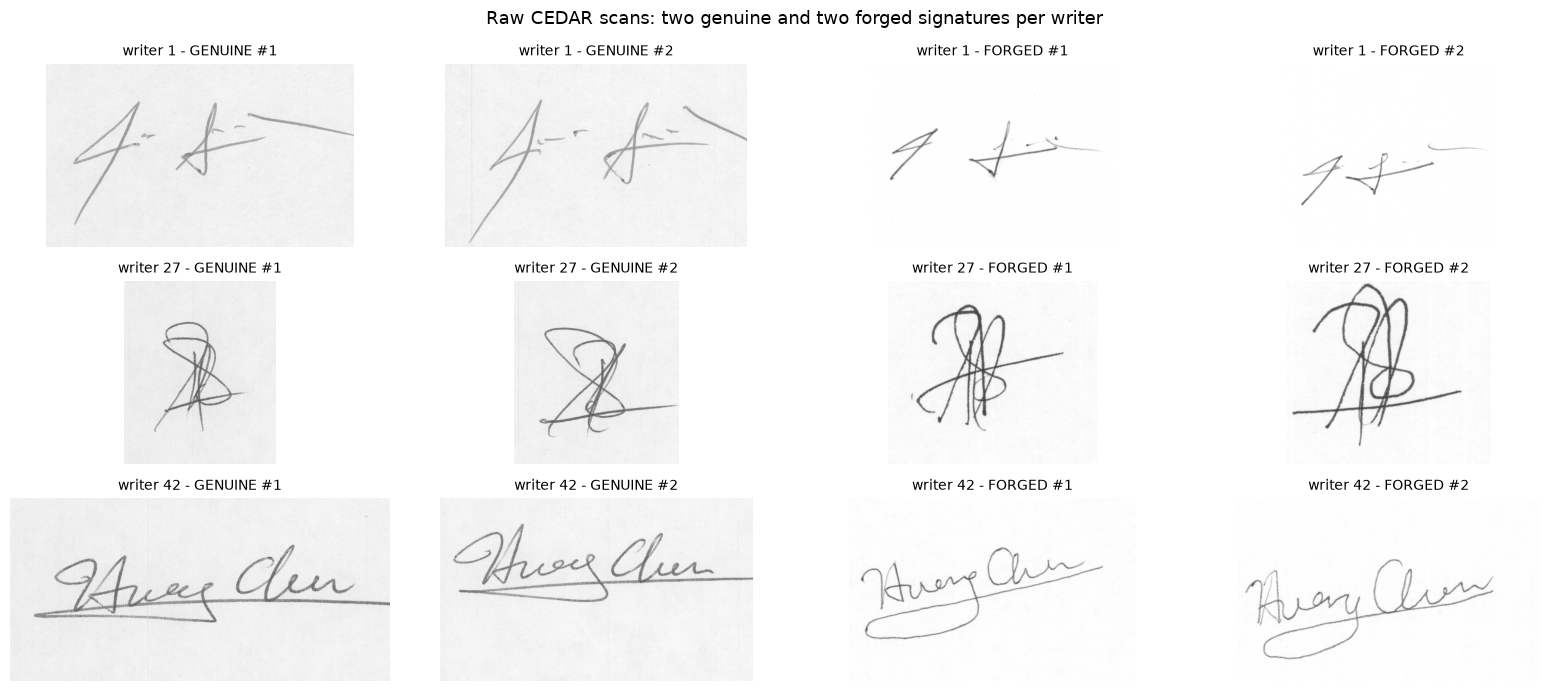

In [3]:
fig, axes = plt.subplots(3, 4, figsize=(16, 7))
for r, w in enumerate([1, 27, 42]):
    for c, (label, i) in enumerate([(0, 1), (0, 2), (1, 1), (1, 2)]):
        k = pick(w, label, i)
        axes[r, c].imshow(cv2.imread(raw_path(k), cv2.IMREAD_GRAYSCALE), cmap="gray", vmin=0, vmax=255)
        axes[r, c].set_title(f"writer {w} - {'GENUINE' if label == 0 else 'FORGED'} #{i}", fontsize=10)
        axes[r, c].axis("off")
plt.suptitle("Raw CEDAR scans: two genuine and two forged signatures per writer", fontsize=13)
plt.tight_layout()
plt.show()

## 2. A hidden shortcut in the data

Looking at the raw scans above, the genuine signatures sit on **grey** paper and the forgeries on **white** paper.
The two classes were scanned differently: for 52 of the 55 writers the genuine files are 1-channel grayscale and the
forgeries 3-channel RGB (writers 29, 39 and 55 are stored as 4-channel RGBA in both classes, with an unused alpha
channel). Measuring every image:

In [4]:
rows = []
for k in range(len(meta)):
    img = cv2.imread(raw_path(k), cv2.IMREAD_UNCHANGED)
    gray = img if img.ndim == 2 else cv2.cvtColor(img[..., :3], cv2.COLOR_BGR2GRAY)
    ink = ink_mask(gray)
    rows.append({"class": "genuine" if meta.label[k] == 0 else "forged",
                 "channels": 1 if img.ndim == 2 else img.shape[2],
                 "paper (median pixel)": float(np.median(gray[~ink])),
                 "ink (mean pixel)": float(gray[ink].mean()),
                 "scan width px": gray.shape[1]})
scan_stats = pd.DataFrame(rows)
scan_stats.groupby("class").agg({"channels": lambda s: sorted(s.unique()), "paper (median pixel)": "mean",
                                 "ink (mean pixel)": "mean", "scan width px": "mean"}).round(1)

,channels,paper (median pixel),ink (mean pixel),scan width px
class,,,,
forged,"[3, 4]",253.6,152.6,552.0
genuine,"[1, 4]",240.0,143.1,535.7


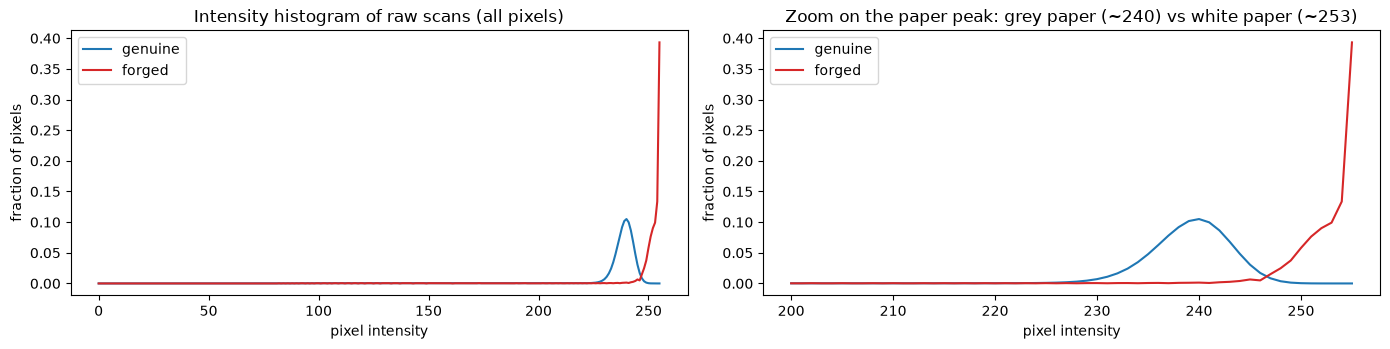

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.6))
for label, color in [(0, "tab:blue"), (1, "tab:red")]:
    idx = meta.index[meta.label == label][::6]
    h = np.zeros(256)
    for k in idx:
        h += np.bincount(cv2.imread(raw_path(k), cv2.IMREAD_GRAYSCALE).ravel(), minlength=256)
    h /= h.sum()
    name = "genuine" if label == 0 else "forged"
    axes[0].plot(h, color=color, label=name)
    axes[1].plot(np.arange(200, 256), h[200:], color=color, label=name)
axes[0].set_title("Intensity histogram of raw scans (all pixels)")
axes[1].set_title("Zoom on the paper peak: grey paper (~240) vs white paper (~253)")
for ax in axes:
    ax.set_xlabel("pixel intensity"); ax.set_ylabel("fraction of pixels"); ax.legend()
plt.tight_layout()
plt.show()

**Shortcut probe.** A logistic regression is given *only* intensity statistics (a 32-bin histogram plus the fraction
and mean of non-white pixels): no stroke shape at all. If it can still separate genuine from forged, a CNN trained
on the same images could learn "grey paper = genuine" instead of anything about the signature. Evaluated with
5-fold cross-validation grouped by writer, on three versions of the input:

In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


def intensity_features(X):
    ch = X[:, 0].reshape(len(X), -1)
    hist = np.stack([np.histogram(r, bins=32, range=(0, 256))[0] for r in ch]) / ch.shape[1]
    nonwhite = ch < 250
    mean_ink = np.array([r[m].mean() if m.any() else 255 for r, m in zip(ch, nonwhite)])[:, None]
    return np.hstack([hist, nonwhite.mean(1, keepdims=True), mean_ink])


probe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
names = {"raw": "raw scans", "canon": "cleaned, grey ink kept", "binary": "cleaned, binary ink (used by the models)"}
res = []
for mode in ["raw", "canon", "binary"]:
    F = intensity_features(np.load(os.path.join(DATA, f"cache_{mode}_X.npy"), mmap_mode="r"))
    acc = cross_val_score(probe, F, meta.label.values, groups=meta.writer.values, cv=GroupKFold(5))
    res.append({"input": names[mode], "intensity-only accuracy": f"{acc.mean():.1%} +/- {acc.std():.1%}"})
pd.DataFrame(res)

,input,intensity-only accuracy
0,raw scans,100.0% +/- 0.0%
1,"cleaned, grey ink kept",83.3% +/- 3.9%
2,"cleaned, binary ink (used by the models)",55.9% +/- 3.6%


**Result.** On raw scans, paper colour alone gives **100 %** accuracy — a model trained on raw CEDAR images can look
perfect while learning nothing about forgery. Keeping grey ink still leaks (83 %). After the preprocessing of
section 3 with binary ink, the probe drops to ~56 %, close to chance. **All models below use the binary-ink input.**

## 3. DIP preprocessing pipeline

Every scan goes through the same steps (`src/preprocess.ipynb`):

**(a) Canonicalisation — removes the scanner differences**

| Step | Operation |
|---|---|
| Grayscale | RGB forgeries converted to one channel |
| Smoothing | 3×3 Gaussian blur before thresholding |
| **Otsu thresholding** | picks the threshold $t$ maximising the between-class variance $\sigma_B^2(t)=\omega_0(t)\,\omega_1(t)\,[\mu_0(t)-\mu_1(t)]^2$ to separate ink from paper |
| **Connected-component analysis** | 8-connected components smaller than 12 px (dust, specks) are removed |
| Crop | bounding box of the remaining ink, 8 px margin |
| Binarisation | ink → 0 (black), paper → 255 (white): no scanner grey levels survive |
| Letterbox resize | aspect-preserving resize (area interpolation) and white padding to 192 × 384 |

**(b) The four-stage enhancement pipeline** (from `DIP_CaseStudy.ipynb`)

| Stage | Operation | Formula |
|---|---|---|
| 1 | **Contrast stretching** | $s = \dfrac{r - r_{min}}{r_{max} - r_{min}} \cdot 255$ |
| 2 | **Median filter** 3×3 (removes salt-and-pepper noise, keeps edges) | $g(x,y) = \operatorname{median}\{f(x+i, y+j)\},\ i,j \in \{-1,0,1\}$ |
| 3 | **High-boost filtering** (sharpens strokes), $k = 1.5$ | $g = f + k\,(f - \bar f)$, where $\bar f$ is the 3×3 mean |
| 4 | **Sobel edge detection** (stroke boundaries) | $M = \sqrt{G_x^2 + G_y^2}$, with $G_x = K * f$, $G_y = K^{T} * f$, $K = \begin{bmatrix}-1&0&1\\-2&0&2\\-1&0&1\end{bmatrix}$ |

Stages 2, 3 and 4 are stacked as the **3 input channels** of the CNN.

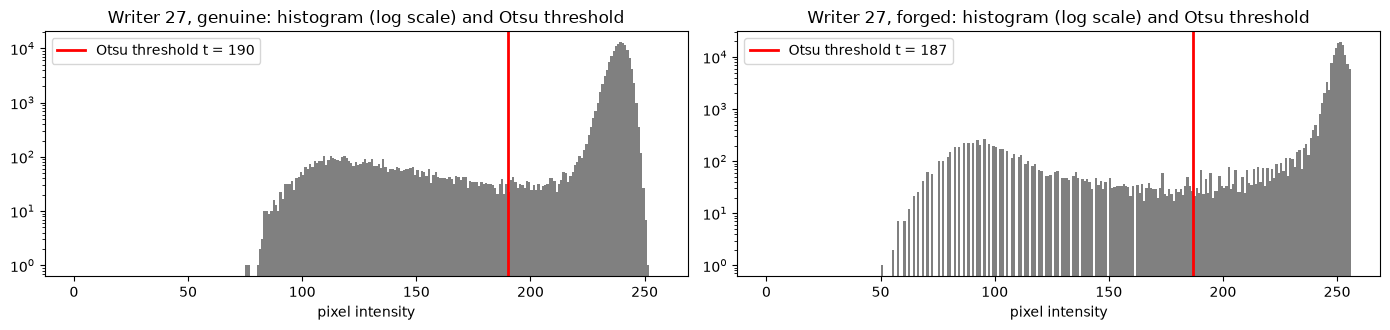

In [7]:
def otsu_steps(gray):
    blur = cv2.GaussianBlur(gray, (3, 3), 0)
    t, mask = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    return t, mask


fig, axes = plt.subplots(1, 2, figsize=(14, 3.4))
for ax, (label, name) in zip(axes, [(0, "genuine"), (1, "forged")]):
    gray = cv2.imread(raw_path(pick(27, label, 1)), cv2.IMREAD_GRAYSCALE)
    t, _ = otsu_steps(gray)
    ax.hist(gray.ravel(), bins=256, range=(0, 256), color="gray", log=True)
    ax.axvline(t, color="red", lw=2, label=f"Otsu threshold t = {t:.0f}")
    ax.set_title(f"Writer 27, {name}: histogram (log scale) and Otsu threshold")
    ax.set_xlabel("pixel intensity"); ax.legend()
plt.tight_layout()
plt.show()

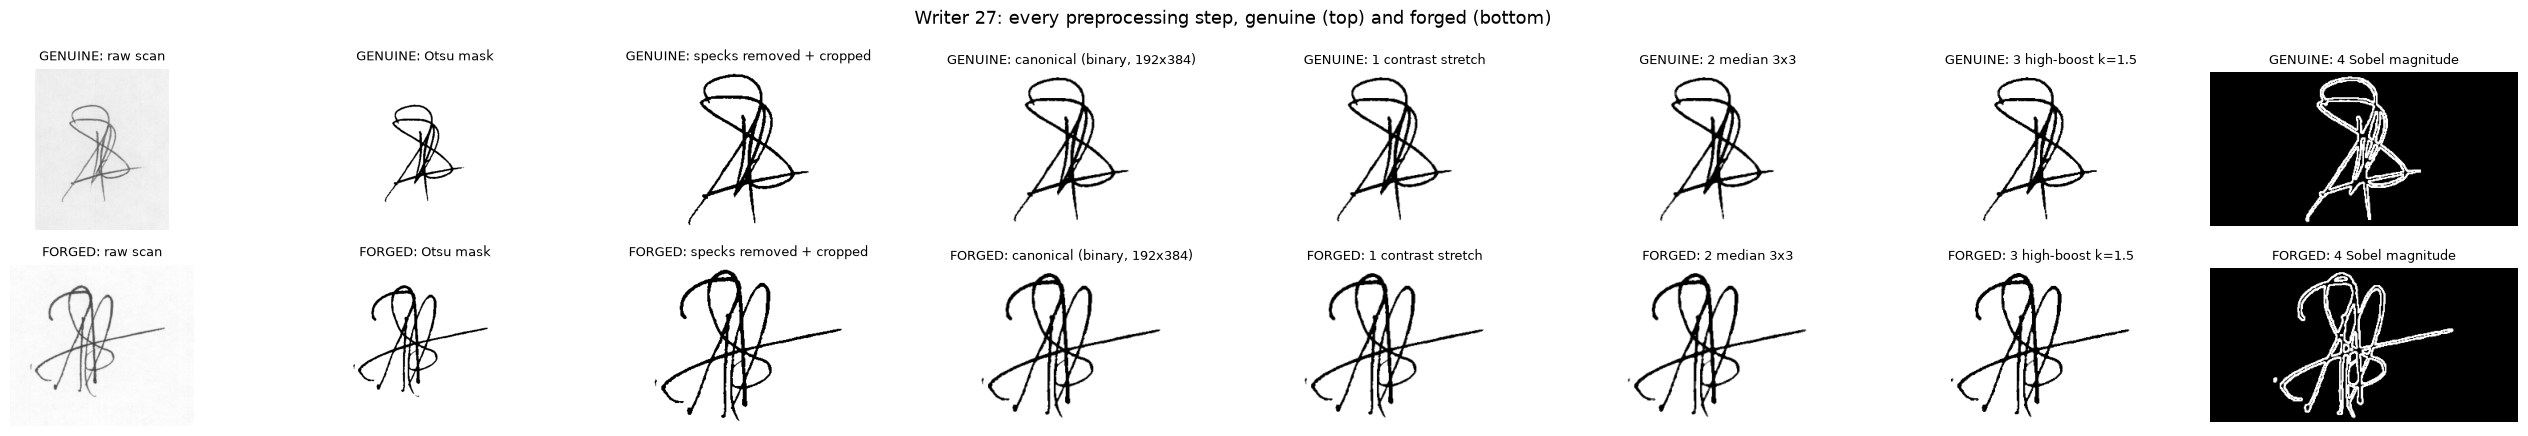

In [8]:
titles = ["raw scan", "Otsu mask", "specks removed + cropped", "canonical (binary, 192x384)",
          "1 contrast stretch", "2 median 3x3", "3 high-boost k=1.5", "4 Sobel magnitude"]
fig, axes = plt.subplots(2, 8, figsize=(26, 4.4))
for r, label in enumerate([0, 1]):
    gray = cv2.imread(raw_path(pick(27, label, 1)), cv2.IMREAD_GRAYSCALE)
    _, otsu = otsu_steps(gray)
    m = ink_mask(gray)
    ys, xs = np.where(m)
    cropped = np.where(m, 0, 255).astype(np.uint8)[max(ys.min() - 8, 0):ys.max() + 9, max(xs.min() - 8, 0):xs.max() + 9]
    canon = canonical_image(gray, binarize=True)
    s1, s2, s3, s4 = pipeline_stages(canon)
    for c, img in enumerate([gray, 255 - otsu, cropped, canon, s1, s2, s3, s4]):
        axes[r, c].imshow(img, cmap="gray", vmin=0, vmax=255)
        axes[r, c].set_title(f"{'GENUINE' if label == 0 else 'FORGED'}: {titles[c]}", fontsize=9)
        axes[r, c].axis("off")
plt.suptitle("Writer 27: every preprocessing step, genuine (top) and forged (bottom)", fontsize=13)
plt.tight_layout()
plt.show()

After canonicalisation the genuine and forged images look alike in every respect except the **shape of the strokes**,
which is exactly what the models should judge. The three stacked channels, shown as one colour image
(red = median, green = high-boost, blue = Sobel):

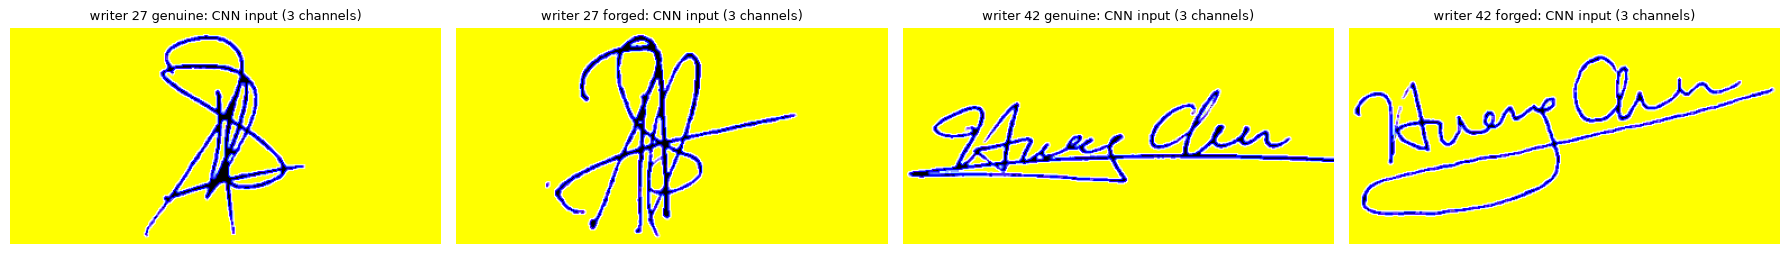

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(18, 2.6))
for ax, (w, label) in zip(axes, [(27, 0), (27, 1), (42, 0), (42, 1)]):
    ch = stages_to_channels(canonical_image(cv2.imread(raw_path(pick(w, label, 1)), cv2.IMREAD_GRAYSCALE), binarize=True))
    ax.imshow(np.transpose(ch, (1, 2, 0)))
    ax.set_title(f"writer {w} {'genuine' if label == 0 else 'forged'}: CNN input (3 channels)", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

**Data augmentation (training only).** Applied to the canonical image *before* the four stages, so the high-boost and
Sobel channels always match the augmented strokes: rotation ±6°, shear ±8°, shrink 0.82–1.0, shift, and random
stroke thickening/thinning by 1 px (morphological erosion/dilation).

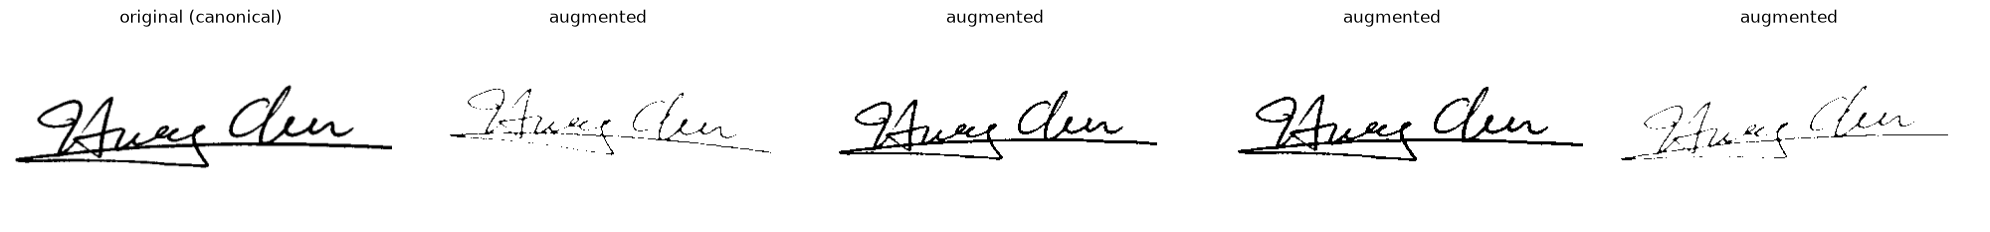

In [10]:
canon = load_gray("binary")[pick(42, 0, 1)]
rng = np.random.default_rng(3)
fig, axes = plt.subplots(1, 5, figsize=(20, 2.4))
axes[0].imshow(canon, cmap="gray"); axes[0].set_title("original (canonical)")
for ax in axes[1:]:
    ax.imshow(augment(np.asarray(canon), rng), cmap="gray"); ax.set_title("augmented")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 4. Evaluation protocol

* **Writer-independent 5-fold cross-validation**: writers (not images) are split into 5 groups. In each fold,
  **11 writers are the test set and are never seen during training**; of the remaining 44, 8 are validation writers
  and 36 are training writers.
* Everything learned or tuned — network weights, best epoch, and the **decision threshold** — uses only training and
  validation writers. The threshold is set at the equal-error point on the validation writers, then applied
  unchanged to the test writers.
* Metrics (positive class = forged):
  * **AUC** — area under the ROC curve (threshold-free, 1.0 = perfect, 0.5 = chance)
  * **FAR** (false acceptance rate) — forgeries accepted as genuine: *fraud gets through*
  * **FRR** (false rejection rate) — genuine signatures rejected: *a real customer is blocked*
  * **EER** — the error rate where FAR = FRR; **accuracy** at the validation-chosen threshold

In [11]:
folds = []
for k in range(5):
    _, tr, va, te = writer_split(fold=k)
    folds.append({"fold": k, "train writers": meta.writer[tr].nunique(), "val writers": meta.writer[va].nunique(),
                  "test writers": sorted(set(meta.writer[te])), "test images": len(te)})
pd.DataFrame(folds).set_index("fold")

,train writers,val writers,test writers,test images
fold,,,,
0,36,8,"[8, 18, 19, 25, 28, 29, 40, 42, 46, 51, 55]",528
1,36,8,"[6, 21, 26, 30, 32, 35, 41, 43, 48, 50, 53]",528
2,36,8,"[5, 10, 16, 17, 22, 24, 27, 33, 38, 45, 52]",528
3,36,8,"[4, 7, 11, 12, 20, 23, 31, 36, 39, 47, 49]",528
4,36,8,"[1, 2, 3, 9, 13, 14, 15, 34, 37, 44, 54]",528


## 5. Models and results

| | Model | Question it answers | Notebook |
|---|---|---|---|
| **A** | Single-image classifier (EfficientNet-B2) | "Is this one signature forged?" | `src/train.ipynb` |
| **B** | Siamese verifier (twin EfficientNet-B2) | "Does this signature match the 5 reference signatures?" | `src/siamese.ipynb` |
| **C** | Per-writer SVM on ImageNet CNN features | compare with the customer's 5 specimens | `src/wd_svm.ipynb` |
| **D** | **Per-writer SVM on writer-ID features (final model)** | compare with the customer's 5 specimens | `src/writer_id.ipynb`, `src/wd_svm.ipynb` |
| **E** | Like D, with an extra forgery head when training the features | compare with the customer's 5 specimens | same |

### 5.1 Model A — single-image classifier
EfficientNet-B2 (ImageNet-pretrained) fine-tuned on the 3-channel input: 15 epochs, AdamW, label smoothing 0.1,
dropout 0.5, weight decay 0.05, cosine learning-rate schedule. The best epoch is chosen on the validation writers.

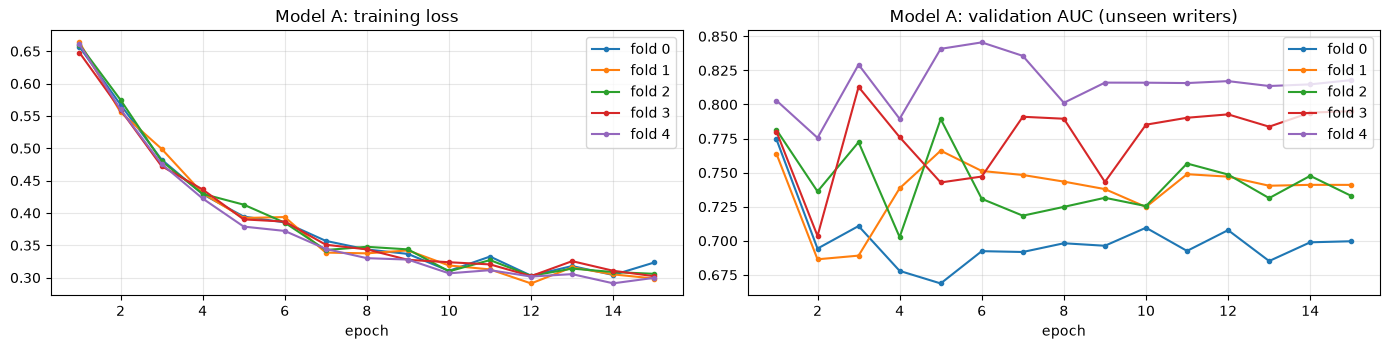

,auc,eer,acc,far,frr
fold,,,,,
0,0.807,0.292,0.691,0.523,0.095
1,0.722,0.352,0.670,0.038,0.621
2,0.781,0.280,0.714,0.284,0.288
3,0.678,0.367,0.583,0.235,0.598
4,0.767,0.309,0.682,0.231,0.405
mean,0.751,0.320,0.668,0.262,0.402
std,0.046,0.034,0.045,0.155,0.197


In [12]:
def show_history(prefix, title):
    fig, axes = plt.subplots(1, 2, figsize=(14, 3.6))
    for k in range(5):
        h = pd.read_csv(os.path.join(RUNS, f"{prefix}_fold{k}", "history.csv"))
        axes[0].plot(h.epoch, h.train_loss, marker=".", label=f"fold {k}")
        axes[1].plot(h.epoch, h.val_auc, marker=".", label=f"fold {k}")
    axes[0].set_title(f"{title}: training loss"); axes[1].set_title(f"{title}: validation AUC (unseen writers)")
    for ax in axes:
        ax.set_xlabel("epoch"); ax.legend(); ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


def fold_table(prefix):
    rows = [{"fold": k, **json.load(open(os.path.join(RUNS, f"{prefix}_fold{k}", "metrics.json")))["test"]}
            for k in range(5)]
    df = pd.DataFrame(rows).set_index("fold")[["auc", "eer", "acc", "far", "frr"]]
    df.loc["mean"] = df.mean()
    df.loc["std"] = df.iloc[:5].std(ddof=0)
    return df.round(3)


show_history("binary", "Model A")
fold_table("binary")

Training loss keeps falling while validation AUC stalls around 0.7–0.8: the model memorises the 36 training writers.
For an **unseen** writer, a skilled forgery is just a plausible signature — there is nothing to compare it with — and
the threshold from validation writers transfers badly (FAR and FRR swing widely between folds).

### 5.2 Model B — Siamese verifier
Twin EfficientNet-B2 with shared weights → 256-d embeddings $e_r, e_q$ of a reference and a questioned signature →
$[\,|e_r-e_q|,\ e_r \odot e_q\,]$ → MLP → forgery score. Trained on (genuine, genuine) and (genuine, forgery) pairs;
at test time the score is averaged over the writer's 5 reference signatures.

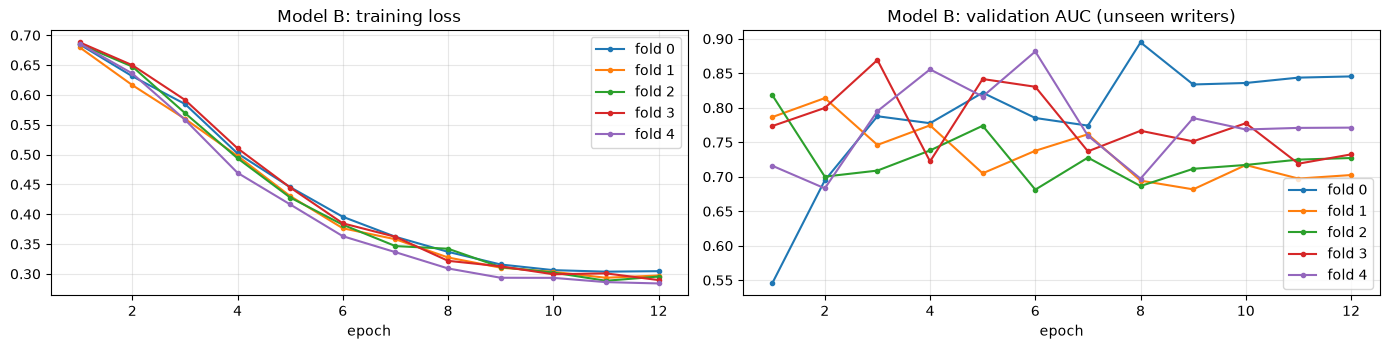

,auc,eer,acc,far,frr
fold,,,,,
0,0.750,0.338,0.628,0.580,0.110
1,0.633,0.402,0.605,0.231,0.603
2,0.645,0.431,0.571,0.424,0.435
3,0.701,0.380,0.628,0.348,0.402
4,0.781,0.281,0.698,0.212,0.416
mean,0.702,0.366,0.626,0.359,0.393
std,0.057,0.052,0.042,0.135,0.159


In [13]:
show_history("siamese", "Model B")
fold_table("siamese")

With only 36 training writers, the Siamese network does not learn a comparison that generalises (AUC 0.70).

### 5.3 Models C, D, E — per-writer verification (how banks verify)

For each test writer an **RBF support vector machine** is trained on CNN feature vectors:
**positives** = the writer's 5 genuine specimen signatures, **negatives** = genuine signatures of the training
writers. *No forgery is needed to build a writer's verifier* — a bank only has genuine specimens. The SVM then scores
the writer's other 19 genuine signatures and all 24 forgeries.

The feature extractor makes the difference:
* **C** — EfficientNet-B2 with ImageNet weights, no fine-tuning
* **D** — EfficientNet-B2 fine-tuned to **identify which of the 36 training writers** signed (cross-entropy, 20 epochs),
  so its features describe *how a person signs* (the SigNet idea, Hafemann et al. 2017)
* **E** — as D, plus a second head trained on genuine vs forged

In [14]:
def wd(tag, mode="binary", n_ref=5):
    return json.load(open(os.path.join(RUNS, "wdsvm", f"{tag}_{mode}_ref{n_ref}.json")))


rows = []
for name, tag in [("C  ImageNet features", "imagenet"), ("C' features of model A", "binary"),
                  ("D  writer-ID features (final)", "writerid"), ("E  writer-ID + forgery head", "writeridF")]:
    r = wd(tag)
    rows.append({"model": name, **{k: f"{r[k + '_mean']:.3f} +/- {r[k + '_std']:.3f}"
                                   for k in ["auc", "eer", "acc", "far", "frr", "mean_writer_eer"]}})
pd.DataFrame(rows).rename(columns={"mean_writer_eer": "per-writer EER"}).set_index("model")

,auc,eer,acc,far,frr,per-writer EER
model,,,,,,
C ImageNet features,0.903 +/- 0.024,0.176 +/- 0.027,0.821 +/- 0.034,0.201 +/- 0.063,0.151 +/- 0.026,0.132 +/- 0.018
C' features of model A,0.860 +/- 0.048,0.216 +/- 0.052,0.756 +/- 0.074,0.305 +/- 0.161,0.166 +/- 0.069,0.167 +/- 0.029
D writer-ID features (final),0.931 +/- 0.018,0.138 +/- 0.029,0.844 +/- 0.045,0.208 +/- 0.097,0.091 +/- 0.026,0.099 +/- 0.016
E writer-ID + forgery head,0.911 +/- 0.024,0.171 +/- 0.034,0.807 +/- 0.043,0.241 +/- 0.097,0.132 +/- 0.034,0.111 +/- 0.020


In [15]:
r = wd("writerid")
pd.DataFrame(r["folds"]).set_index("fold")[["auc", "eer", "acc", "far", "frr", "mean_writer_eer"]].round(3)

,auc,eer,acc,far,frr,mean_writer_eer
fold,,,,,,
0,0.954,0.095,0.907,0.072,0.120,0.085
1,0.927,0.141,0.852,0.186,0.100,0.076
2,0.914,0.146,0.822,0.231,0.110,0.111
3,0.909,0.184,0.772,0.371,0.048,0.100
4,0.948,0.125,0.867,0.178,0.077,0.121


Fine-tuning for **writer identity** (D) beats ImageNet features (C); fine-tuning for "forged vs genuine" (C', E)
makes the features *worse*, because they learn forgery style instead of who is signing.

### 5.4 Comparison of all models

,auc,eer,acc,far,frr
model,,,,,
A single-image classifier,0.751 +/- 0.046,0.320 +/- 0.034,0.668 +/- 0.045,0.262 +/- 0.155,0.402 +/- 0.197
B Siamese,0.702 +/- 0.057,0.366 +/- 0.052,0.626 +/- 0.042,0.359 +/- 0.135,0.393 +/- 0.159
"C SVM, ImageNet features",0.903 +/- 0.024,0.176 +/- 0.027,0.821 +/- 0.034,0.201 +/- 0.063,0.151 +/- 0.026
"D SVM, writer-ID features",0.931 +/- 0.018,0.138 +/- 0.029,0.844 +/- 0.045,0.208 +/- 0.097,0.091 +/- 0.026
"E SVM, writer-ID + forgery head",0.911 +/- 0.024,0.171 +/- 0.034,0.807 +/- 0.043,0.241 +/- 0.097,0.132 +/- 0.034


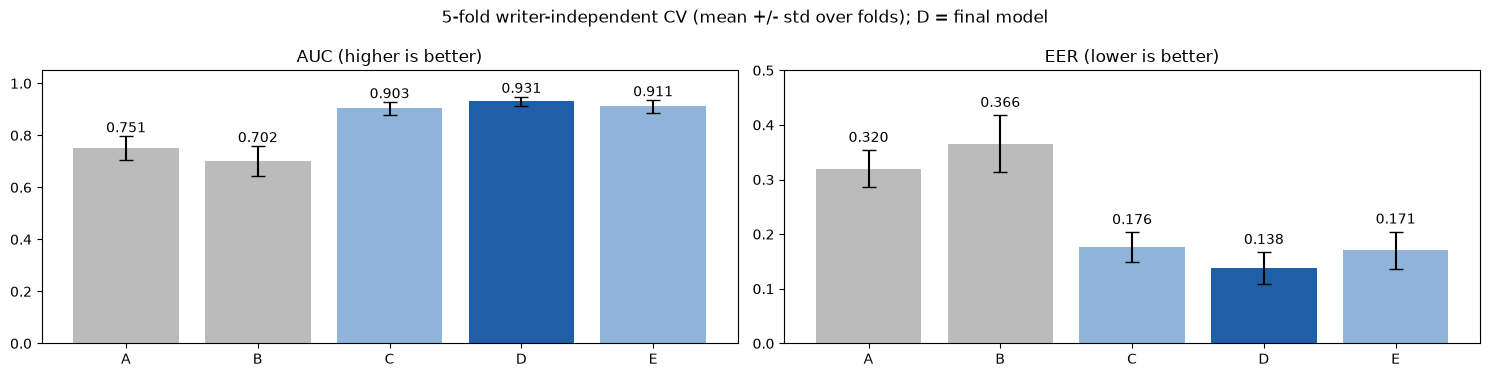

In [16]:
summary = []
for name, prefix in [("A  single-image classifier", "binary"), ("B  Siamese", "siamese")]:
    df = fold_table(prefix)
    summary.append({"model": name, **{k: (df.loc["mean", k], df.loc["std", k]) for k in ["auc", "eer", "acc", "far", "frr"]}})
for name, tag in [("C  SVM, ImageNet features", "imagenet"), ("D  SVM, writer-ID features", "writerid"),
                  ("E  SVM, writer-ID + forgery head", "writeridF")]:
    r = wd(tag)
    summary.append({"model": name, **{k: (r[k + "_mean"], r[k + "_std"]) for k in ["auc", "eer", "acc", "far", "frr"]}})

table = pd.DataFrame([{"model": s["model"], **{k: f"{s[k][0]:.3f} +/- {s[k][1]:.3f}" for k in ["auc", "eer", "acc", "far", "frr"]}}
                      for s in summary]).set_index("model")
display(table)

fig, axes = plt.subplots(1, 2, figsize=(15, 3.8))
labels = [s["model"].split("  ")[0] for s in summary]
colors = ["#bbbbbb", "#bbbbbb", "#8fb3d9", "#1f5fa8", "#8fb3d9"]
for ax, key, title in [(axes[0], "auc", "AUC (higher is better)"), (axes[1], "eer", "EER (lower is better)")]:
    vals, errs = [s[key][0] for s in summary], [s[key][1] for s in summary]
    ax.bar(labels, vals, yerr=errs, color=colors, capsize=5)
    for i, (v, e) in enumerate(zip(vals, errs)):
        ax.text(i, v + e + 0.015, f"{v:.3f}", ha="center", fontsize=10)
    ax.set_title(title); ax.set_ylim(0, 1.05 if key == "auc" else 0.5)
plt.suptitle("5-fold writer-independent CV (mean +/- std over folds); D = final model", fontsize=12)
plt.tight_layout()
plt.show()

**ROC curves and confusion matrix.** Test scores of all 5 folds pooled together (each fold scored by its own model,
on its own unseen writers). For C and D the per-writer SVMs are rebuilt from the saved CNN features (a few seconds).

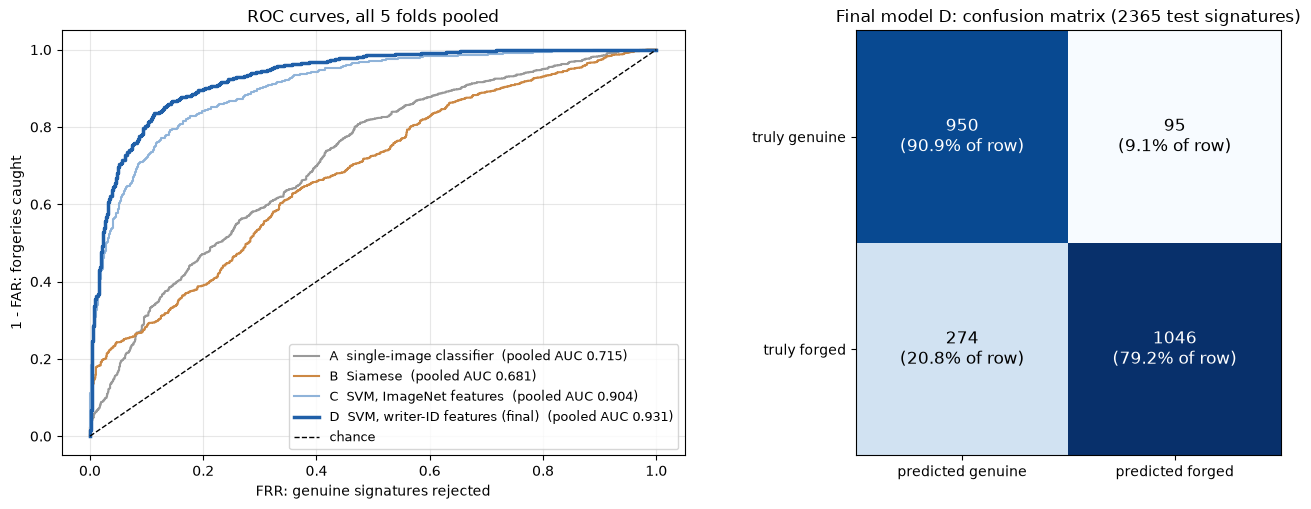

Final model D, all folds pooled: accuracy 84.4%, FAR 20.8%, FRR 9.1%


In [17]:
def saved_scores(prefix):
    ys, ss, preds = [], [], []
    for k in range(5):
        _, y, s = np.load(os.path.join(RUNS, f"{prefix}_fold{k}", "test_scores.npy"))
        thr = json.load(open(os.path.join(RUNS, f"{prefix}_fold{k}", "metrics.json")))["test"]["thr"]
        ys.append(y); ss.append(s); preds.append(s >= thr)
    return np.concatenate(ys), np.concatenate(ss), np.concatenate(preds)


def svm_scores(tag, n_ref=5):
    ys, ss, preds = [], [], []
    for k in range(5):
        F = cnn_features(tag, "binary", k)
        _, tr, va, te = writer_split(fold=k)
        neg = F[tr[meta.label.values[tr] == 0]]
        yv, sv, _ = score_writers(F, meta, sorted(set(meta.writer[va])), neg, n_ref)
        thr, _ = eer_threshold(yv, sv)
        yt, st, _ = score_writers(F, meta, sorted(set(meta.writer[te])), neg, n_ref)
        ys.append(yt); ss.append(st); preds.append(st >= thr)
    return np.concatenate(ys), np.concatenate(ss), np.concatenate(preds)


scores = {"A  single-image classifier": saved_scores("binary"), "B  Siamese": saved_scores("siamese"),
          "C  SVM, ImageNet features": svm_scores("imagenet"), "D  SVM, writer-ID features (final)": svm_scores("writerid")}

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
for (name, (y, s, _)), color in zip(scores.items(), ["#999999", "#cc8844", "#8fb3d9", "#1f5fa8"]):
    fpr, tpr, _ = roc_curve(y, s)
    axes[0].plot(fpr, tpr, color=color, lw=2.5 if name.startswith("D") else 1.5,
                 label=f"{name}  (pooled AUC {roc_auc_score(y, s):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=1, label="chance")
axes[0].set_xlabel("FRR: genuine signatures rejected"); axes[0].set_ylabel("1 - FAR: forgeries caught")
axes[0].set_title("ROC curves, all 5 folds pooled"); axes[0].legend(fontsize=9, loc="lower right"); axes[0].grid(alpha=0.3)

y, s, pred = scores["D  SVM, writer-ID features (final)"]
cm = confusion_matrix(y, pred)
axes[1].imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        axes[1].text(j, i, f"{cm[i, j]}\n({cm[i, j] / cm[i].sum():.1%} of row)", ha="center", va="center",
                     fontsize=12, color="white" if cm[i, j] > cm.max() / 2 else "black")
axes[1].set_xticks([0, 1], ["predicted genuine", "predicted forged"])
axes[1].set_yticks([0, 1], ["truly genuine", "truly forged"])
axes[1].set_title(f"Final model D: confusion matrix ({len(y)} test signatures)")
plt.tight_layout()
plt.show()
print(f"Final model D, all folds pooled: accuracy {(pred == y).mean():.1%}, "
      f"FAR {(~pred[y == 1]).mean():.1%}, FRR {pred[y == 0].mean():.1%}")

*(Pooled AUC differs slightly from the mean of the per-fold AUCs in the tables, because pooling also mixes the
score scales of the five fold models.)*

### 5.5 How many specimen signatures are needed?

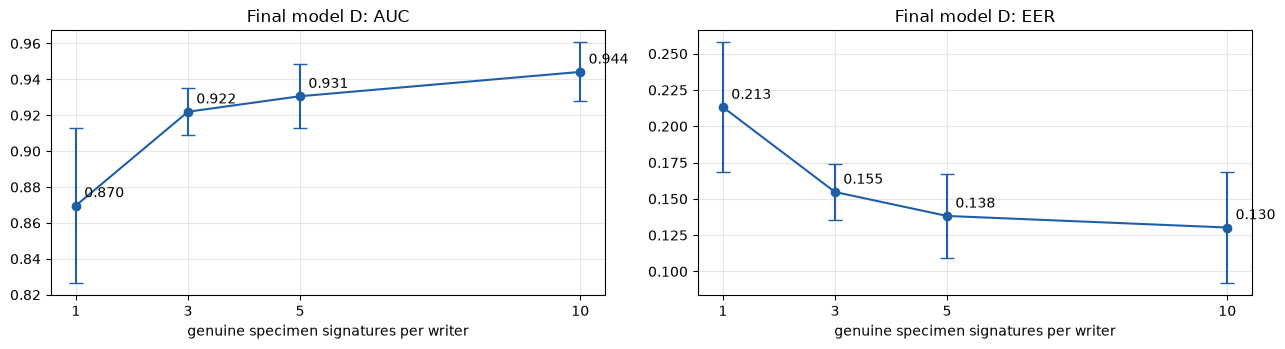

In [18]:
refs = [1, 3, 5, 10]
rs = [wd("writerid", n_ref=n) for n in refs]
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
for ax, key, title in [(axes[0], "auc", "AUC"), (axes[1], "eer", "EER")]:
    ax.errorbar(refs, [r[key + "_mean"] for r in rs], yerr=[r[key + "_std"] for r in rs], marker="o", capsize=5,
                color="#1f5fa8")
    for n, r in zip(refs, rs):
        ax.annotate(f"{r[key + '_mean']:.3f}", (n, r[key + "_mean"]), textcoords="offset points", xytext=(6, 6))
    ax.set_xticks(refs); ax.set_xlabel("genuine specimen signatures per writer"); ax.set_title(f"Final model D: {title}")
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Even one specimen (AUC 0.870) beats the single-image classifier (0.751); 5–10 specimens give AUC 0.93–0.94.

### 5.6 Leak check: is the model reading the signature or the scanner?
The forgeries were also scanned at a different resolution, so stroke thickness could still carry a scanner trace.
Re-running the verifiers on a **stroke-normalised** input (skeletonised, then every stroke redrawn 3 px wide, leaving
only the pen trajectory):

In [19]:
rows = []
for name, tag in [("C  ImageNet features", "imagenet"), ("D  writer-ID features (final)", "writerid")]:
    a, b = wd(tag, "binary"), wd(tag, "skel")
    rows.append({"model": name, "AUC, normal input": f"{a['auc_mean']:.3f}", "AUC, stroke-normalised": f"{b['auc_mean']:.3f}",
                 "change": f"{b['auc_mean'] - a['auc_mean']:+.3f}"})
pd.DataFrame(rows).set_index("model")

,"AUC, normal input","AUC, stroke-normalised",change
model,,,
C ImageNet features,0.903,0.879,-0.024
D writer-ID features (final),0.931,0.923,-0.008


Removing stroke width costs D less than 0.01 AUC: the final model reads the **shape** of the signature, not
scanner artefacts.

## 6. Explainability: Grad-CAM

Grad-CAM (Selvaraju et al., 2017) weights each channel $c$ of the last convolutional feature map $A$ by the average
gradient of the score $y$, $\;\alpha_c = \frac{1}{Z}\sum_{i,j} \frac{\partial y}{\partial A^c_{ij}}$, and shows
$\operatorname{ReLU}\big(\sum_c \alpha_c A^c\big)$ upsampled to the image. Red = regions that drove the decision.

**Model A** (single-image classifier), test writers of fold 0 (generated by `src/gradcam.ipynb`):

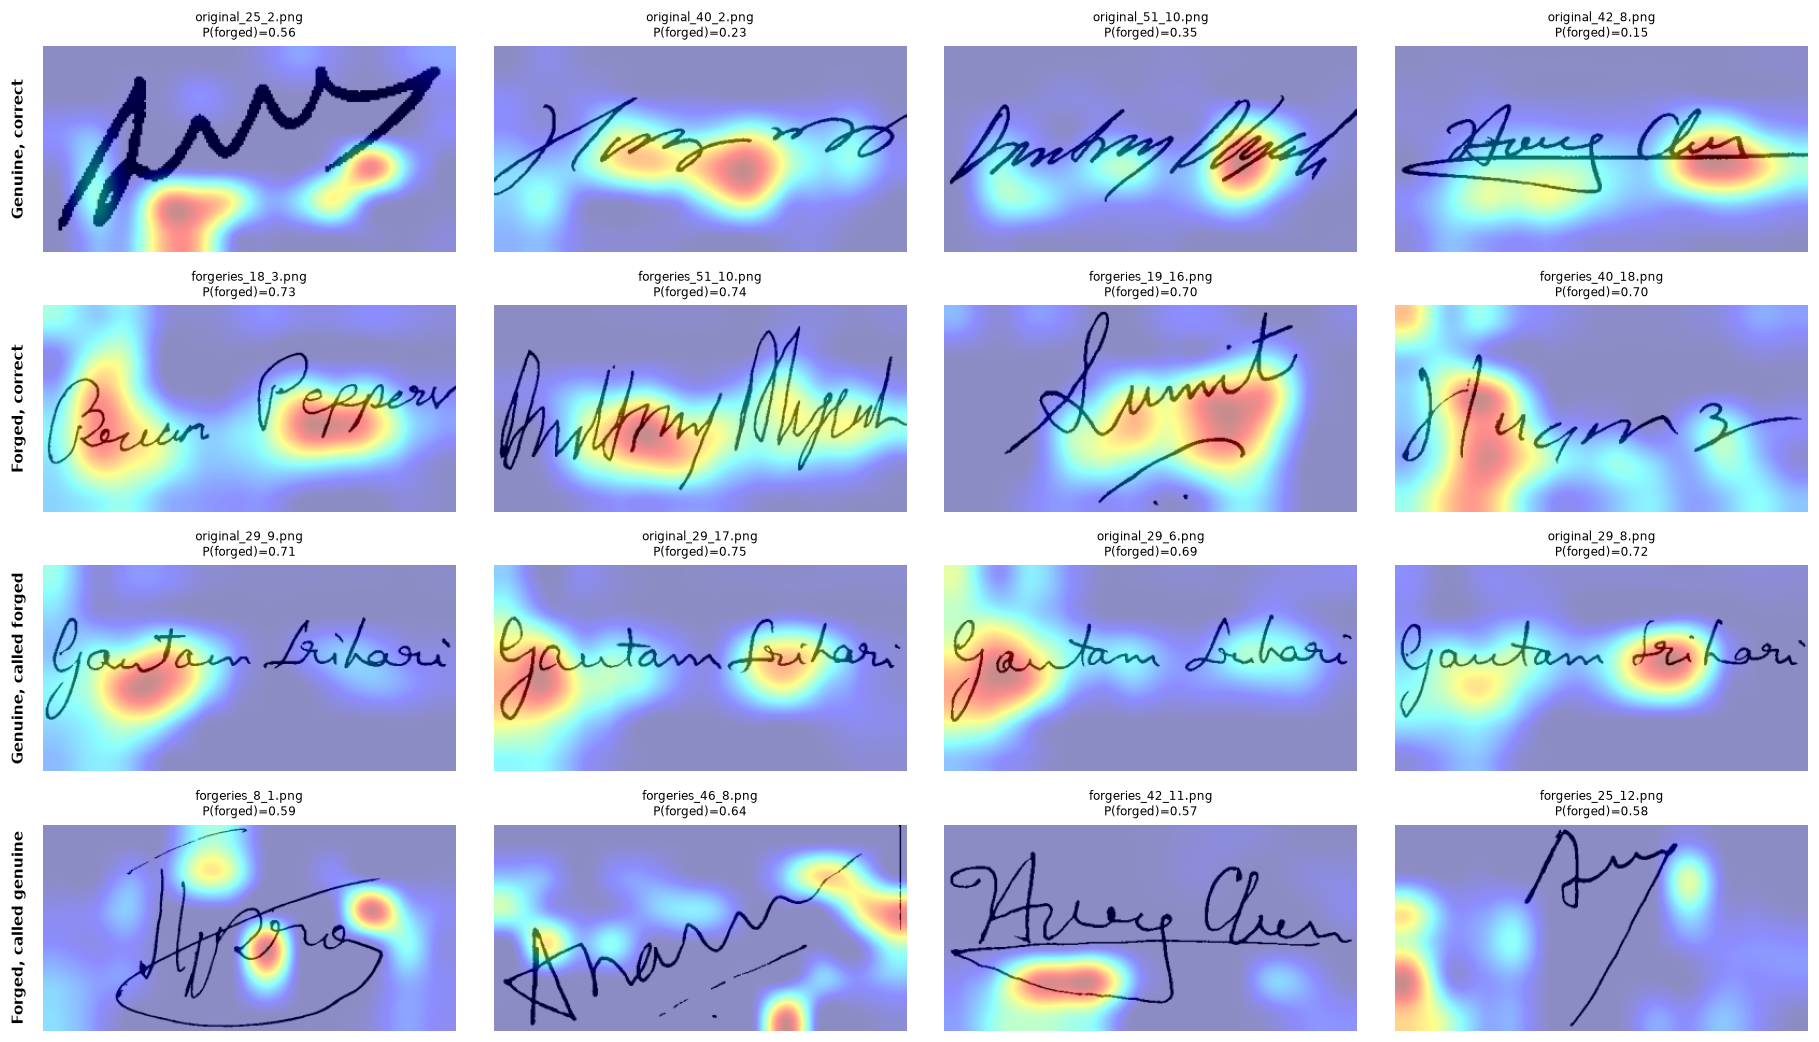

In [20]:
display(Image(os.path.join(RUNS, "binary_fold0", "gradcam_grid.png"), width=1100))

All false rejections in this fold come from one writer (#29) whose careful cursive "looks forged" to model A, and
missed forgeries put attention on blank paper. For the final model D, the gradient is taken through the writer's SVM
score $s(x) = -\big(\sum_i a_i\, e^{-\gamma\,\lVert sv_i - f(x)\rVert^2} + b\big)$, so red marks regions that look
**unlike this writer's specimens** — shown in the demo below.

## 7. Final model demo: verifying a customer's signatures

Scenario: a bank holds **5 genuine specimen signatures** of a customer. Signatures on new cheques are checked against
them. The model (fold 0) has never seen this customer; the decision threshold was fixed on the validation writers.

Customer = writer 42; decision threshold (from validation writers) = -0.029; SVM built from 5 specimens, 84 support vectors


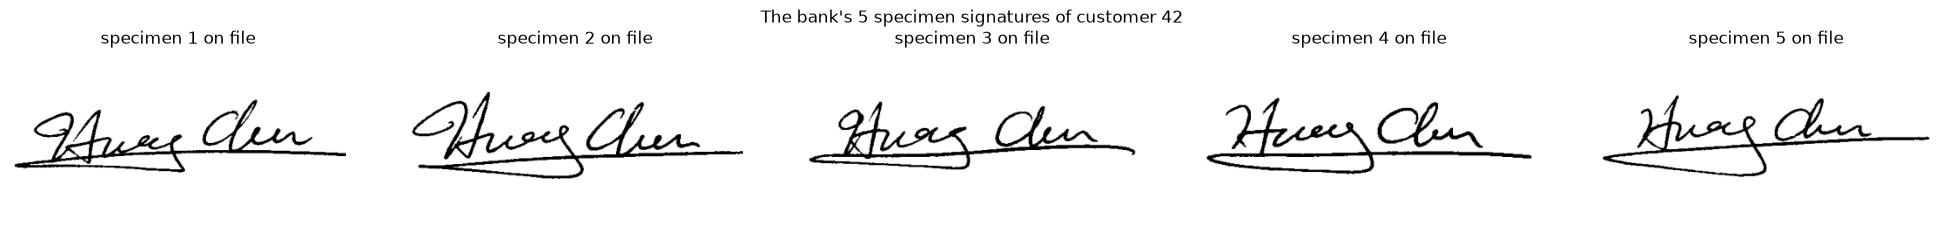

In [21]:
FOLD, CUSTOMER = 0, 42
_, tr, va, te = writer_split(fold=FOLD)
assert CUSTOMER in set(meta.writer[te]), "the demo customer must be a test writer of this fold"
G = load_gray("binary")
F = cnn_features("writerid", "binary", FOLD)
neg = F[tr[meta.label.values[tr] == 0]]
yv, sv, _ = score_writers(F, meta, sorted(set(meta.writer[va])), neg, 5)
thr, _ = eer_threshold(yv, sv)

model = build_model(pretrained=False).to(DEVICE).eval()
model.features.load_state_dict(torch.load(os.path.join(RUNS, f"writerid_fold{FOLD}", "best.pt"), map_location=DEVICE)["features"])

svm, quest = fit_writer_svm(F, meta, CUSTOMER, neg, 5)
print(f"Customer = writer {CUSTOMER}; decision threshold (from validation writers) = {thr:+.3f}; "
      f"SVM built from 5 specimens, {len(svm.support_)} support vectors")

fig, axes = plt.subplots(1, 5, figsize=(20, 2.3))
for i, ax in enumerate(axes, start=1):
    ax.imshow(G[pick(CUSTOMER, 0, i)], cmap="gray"); ax.set_title(f"specimen {i} on file"); ax.axis("off")
plt.suptitle(f"The bank's 5 specimen signatures of customer {CUSTOMER}", fontsize=12)
plt.tight_layout()
plt.show()

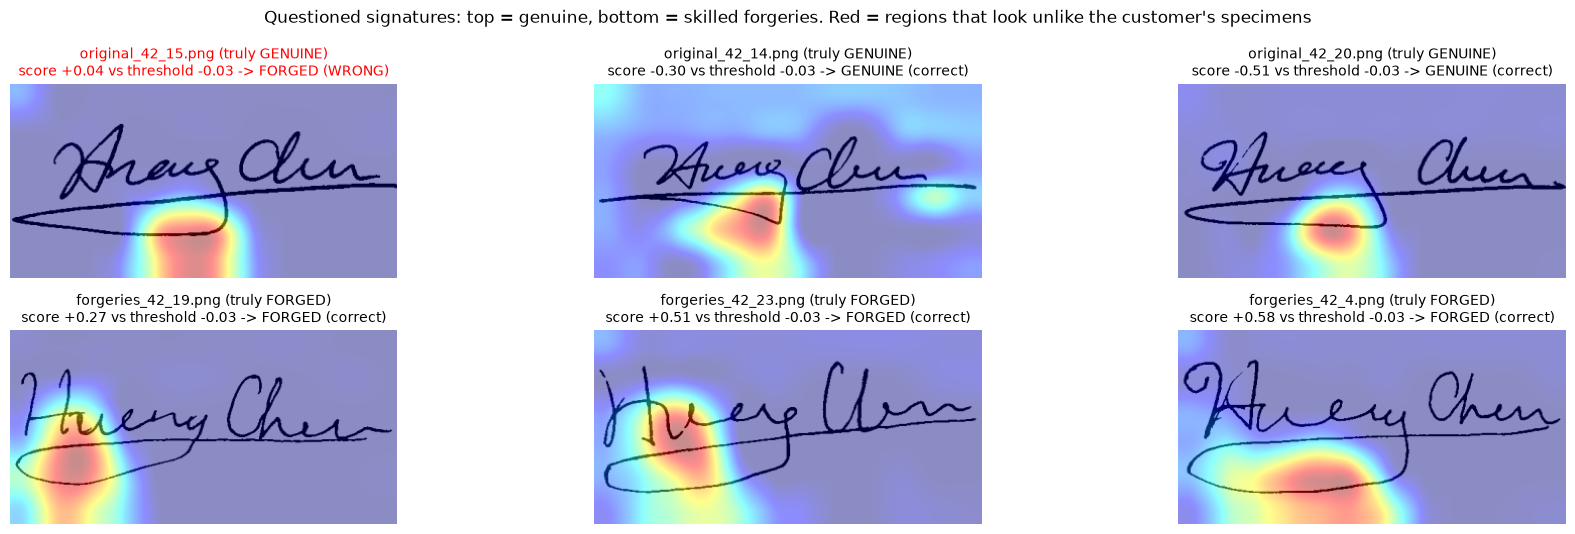

In [22]:
cam = SVMGradCAM(model, svm, DEVICE)
rng = np.random.default_rng(1)
gen = rng.choice([q for q in quest if meta.label[q] == 0], 3, replace=False)
forg = rng.choice([q for q in quest if meta.label[q] == 1], 3, replace=False)
fig, axes = plt.subplots(2, 3, figsize=(18, 5.4))
for r, picks in enumerate([gen, forg]):
    for c, k in enumerate(picks):
        x = torch.from_numpy(to_input(np.asarray(G[k])))[None].to(DEVICE)
        heat, s = cam(x)
        verdict = "FORGED" if s >= thr else "GENUINE"
        truth = "FORGED" if meta.label[k] else "GENUINE"
        ok = "correct" if verdict == truth else "WRONG"
        axes[r, c].imshow(overlay(np.asarray(G[k]), heat))
        axes[r, c].set_title(f"{os.path.basename(meta.path[k])} (truly {truth})\n"
                             f"score {s:+.2f} vs threshold {thr:+.2f} -> {verdict} ({ok})",
                             fontsize=10, color="black" if ok == "correct" else "red")
        axes[r, c].axis("off")
plt.suptitle("Questioned signatures: top = genuine, bottom = skilled forgeries. "
             "Red = regions that look unlike the customer's specimens", fontsize=12)
plt.tight_layout()
plt.show()

Wrong decisions are shown in red: the verifier is not perfect, and a genuine signature that differs from the
specimens more than usual can be rejected (a false rejection). **Every test writer of fold 0** (19 questioned genuine +
24 forged signatures each):

In [23]:
rows = []
for w in sorted(set(meta.writer[te])):
    svm_w, q = fit_writer_svm(F, meta, w, neg, 5)
    s = -svm_w.decision_function(F[q])
    y = meta.label.values[q]
    rows.append({"writer": w, "genuine accepted": f"{(s[y == 0] < thr).sum()} / {(y == 0).sum()}",
                 "forgeries caught": f"{(s[y == 1] >= thr).sum()} / {(y == 1).sum()}",
                 "accuracy": f"{((s >= thr) == y).mean():.1%}", "AUC": round(roc_auc_score(y, s), 3)})
pd.DataFrame(rows).set_index("writer")

,genuine accepted,forgeries caught,accuracy,AUC
writer,,,,
8,4 / 19,22 / 24,60.5%,0.586
18,18 / 19,23 / 24,95.3%,0.982
19,19 / 19,24 / 24,100.0%,1.000
25,18 / 19,20 / 24,88.4%,0.941
28,18 / 19,19 / 24,86.0%,0.978
29,19 / 19,24 / 24,100.0%,1.000
40,15 / 19,23 / 24,88.4%,0.961
42,18 / 19,24 / 24,97.7%,1.000
46,18 / 19,21 / 24,90.7%,0.910


## 8. Conclusion

**Findings**
1. **The raw CEDAR images contain a shortcut**: genuine and forged signatures were scanned differently (grey vs white
   paper; grayscale vs RGB files for 52 of the 55 writers), so paper colour alone classifies them 100 % correctly. DIP preprocessing — Otsu
   thresholding, connected-component cleaning, binarisation — removes it (probe accuracy 100 % → 56 %).
2. **Judging one signature in isolation does not work for unseen writers** (model A, AUC 0.751): a skilled forgery is
   a plausible signature unless it is compared with the real one.
3. **Comparing with the writer's specimens works** (model D, AUC 0.931 ± 0.018, EER 13.8 %, accuracy 84.4 %), with
   features learned for writer identification and a per-writer SVM that needs no forgery examples.
4. The verifier passes a leak check (stroke-normalised input, AUC 0.923) and its Grad-CAM heatmaps point at the
   strokes where a forgery departs from the specimens.

**Limitations.** Performance varies by writer: in fold 0 most writers are verified with 86–100 % accuracy, but for
writer 8 only 4 of 19 genuine signatures are accepted (AUC 0.59), likely because that writer's signatures vary more
than 5 specimens capture. CEDAR is small (55 writers), so the feature extractor learns from only 36 writers per fold. At the
equal-error threshold, about 1 in 5 forgeries is still accepted (FAR 20.8 %); a bank would choose a stricter
threshold, trading more rejected genuine signatures for fewer accepted forgeries. Grad-CAM heatmaps are coarse
(the last feature map is 6 × 12).

**Future work.** Train the writer-identification network on a larger dataset (e.g. GPDS, BHSig260), higher input
resolution to capture stroke tremor, and cross-dataset testing.

### References
1. M. K. Kalera, S. Srihari, A. Xu, "Offline signature verification and identification using distance statistics,"
   *International Journal of Pattern Recognition and Artificial Intelligence*, 2004. (CEDAR dataset)
2. N. Otsu, "A threshold selection method from gray-level histograms," *IEEE Trans. Systems, Man, and Cybernetics*, 1979.
3. R. C. Gonzalez, R. E. Woods, *Digital Image Processing*, Pearson. (contrast stretching, median, high-boost, Sobel)
4. M. Tan, Q. V. Le, "EfficientNet: Rethinking model scaling for convolutional neural networks," ICML 2019.
5. L. G. Hafemann, R. Sabourin, L. S. Oliveira, "Learning features for offline handwritten signature verification
   using deep convolutional neural networks," *Pattern Recognition*, 2017. (SigNet)
6. R. R. Selvaraju et al., "Grad-CAM: Visual explanations from deep networks via gradient-based localization," ICCV 2017.